# Laboratorio 3 — Deep Learning: Reconocimiento de Lenguaje de Señas (ASL)

CC3084 – Data Science | Semestre II 2026

**Contexto:** SignBridge, un traductor de ASL en tiempo real. Este notebook construye y evalúa el primer prototipo del motor de reconocimiento: un clasificador de letras del alfabeto ASL a partir de imágenes de manos.

## Integrantes

- Pedro Avila
- Brandon Rivera
- Javier Lopez
- Javier Cifuentes

## Índice

1. Setup y carga de datos
2. Ejercicio 1 — Ejemplos de letras y variabilidad intra-clase
3. Ejercicio 2 — Análisis exploratorio de datos (EDA)
4. Ejercicio 3 — Preprocesamiento de imágenes
5. Ejercicio 4 — Modelos CNN
6. Ejercicio 5 — Red fully-connected simple
7. Ejercicio 6 — Modelo con otro algoritmo (Random Forest)
8. Ejercicio 7 — Image augmentation
9. Ejercicio 8 — Prueba con señas propias del grupo
10. Ejercicio 9 — Reflexión de accesibilidad y sesgo
11. Ejercicio 10 — Conclusiones y comparación final

## 1. Setup y carga de datos

El dataset **ASL Alphabet** (Kaggle, `grassknoted/asl-alphabet`) se descargó vía la API de Kaggle a `data/raw/`. Contiene 29 carpetas (una por clase: A-Z, `del`, `nothing`, `space`) con imágenes `.jpg` de 200x200 píxeles a color.

Las funciones de carga, submuestreo y preprocesamiento están en `src/data_utils.py`, las arquitecturas de modelos en `src/models.py`, y las rutinas de entrenamiento/evaluación en `src/train_utils.py`, para mantener el notebook enfocado en el análisis y la discusión de resultados.

In [1]:
import sys, os, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch

REPO_ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "src"))
import data_utils as du
import models as mdl
import train_utils as tu

os.chdir(REPO_ROOT)  # trabajar con rutas relativas a la raiz del repo (idempotente: seguro correr esta celda mas de una vez)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Clases ({len(du.CLASSES)}): {du.CLASSES}")

Device: cpu
Clases (29): ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 2. Ejercicio 1 — Ejemplos de letras y variabilidad intra-clase

Mostramos ejemplos de varias letras del alfabeto ASL, con varias muestras de una misma letra para observar qué tanto varía la seña dentro de una misma clase (posición de la mano, ángulo, iluminación, encuadre).

Elegimos deliberadamente **A, B, M, N, S** — las últimas tres (M/N/S) son un grupo que el enunciado señala como visualmente confundible, así que las usamos también como preparación para esa discusión más adelante.

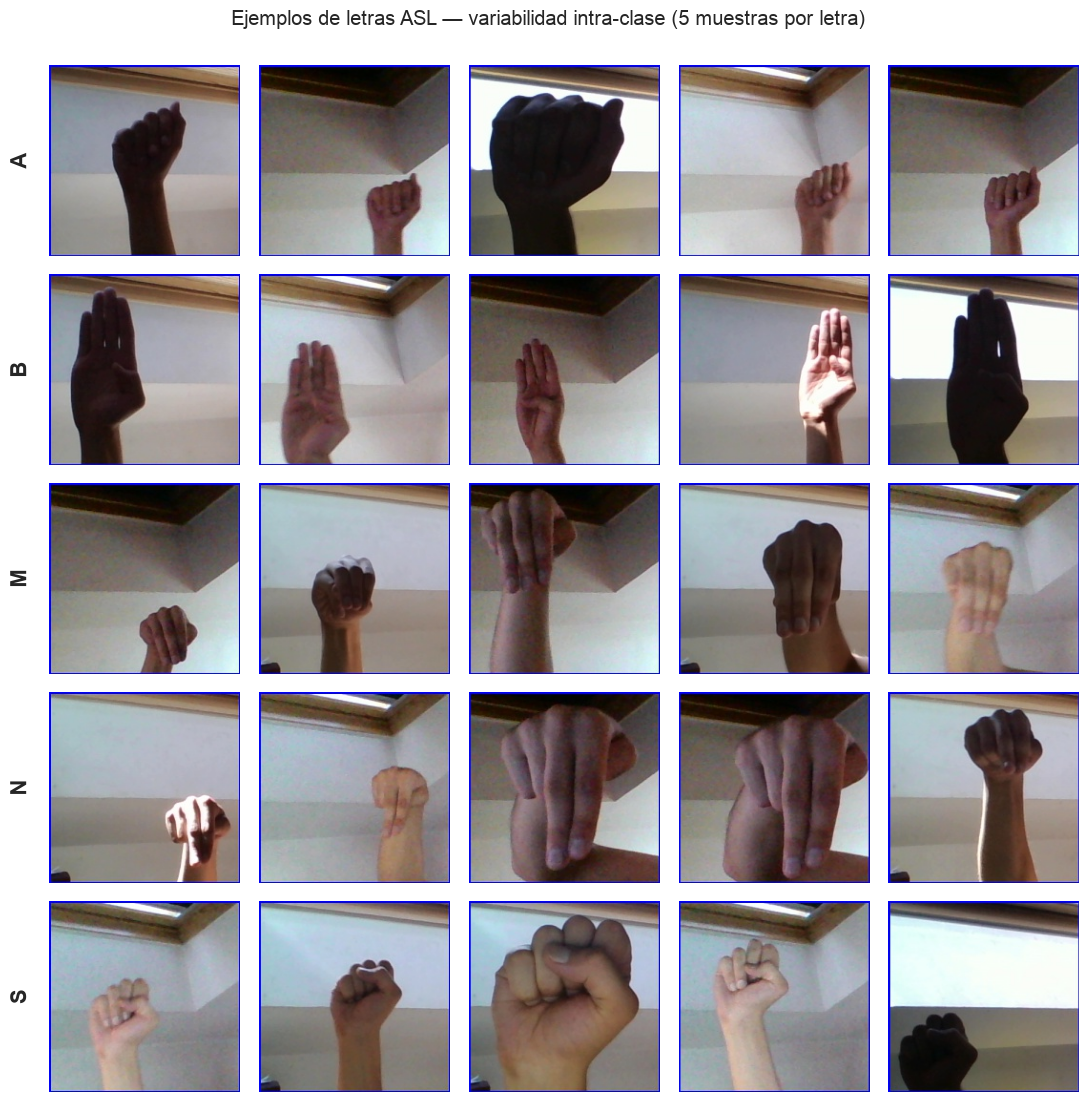

In [5]:
demo_letters = ["A", "B", "M", "N", "S"]
n_samples = 5
rng = np.random.default_rng(SEED)

files_by_class = du.list_class_files()

fig, axes = plt.subplots(len(demo_letters), n_samples, figsize=(2.2 * n_samples, 2.2 * len(demo_letters)))
for row, letter in enumerate(demo_letters):
    files = files_by_class[letter]
    chosen = rng.choice(len(files), size=n_samples, replace=False)
    for col, idx in enumerate(chosen):
        img = Image.open(files[idx])
        ax = axes[row, col]
        ax.imshow(img)
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(letter, fontsize=14)
            ax.text(-0.15, 0.5, letter, fontsize=16, fontweight="bold", transform=ax.transAxes,
                    ha="center", va="center", rotation=90)
plt.suptitle("Ejemplos de letras ASL — variabilidad intra-clase (5 muestras por letra)", y=1.0)
plt.tight_layout()
plt.show()

## 3. Ejercicio 2 — Análisis exploratorio de datos (EDA)

Generamos varias preguntas guía para entender el dataset antes de modelar:

1. ¿Qué resolución y formato tienen las imágenes?
2. ¿Está balanceado el dataset entre las 29 clases?
3. ¿Qué letras se confunden visualmente entre sí?
4. ¿Qué tan variados son el fondo, la iluminación y el tono de piel entre imágenes?
5. ¿Cómo se debe construir el conjunto de entrenamiento/validación/prueba dado cómo se recolectaron los datos?

### 3.1 Resolución y formato

In [ ]:
sample_files = [files_by_class[c][0] for c in du.CLASSES[:6]]
rows = []
for f in sample_files:
    with Image.open(f) as img:
        rows.append({"archivo": f.name, "formato": img.format, "modo": img.mode, "tamano": img.size})
display(pd.DataFrame(rows))

total_files = sum(len(v) for v in files_by_class.values())
print(f"Total de imagenes de entrenamiento (todas las clases): {total_files}")

,archivo,formato,modo,tamano
0,A1.jpg,JPEG,RGB,"(200, 200)"
1,B1.jpg,JPEG,RGB,"(200, 200)"
2,C1.jpg,JPEG,RGB,"(200, 200)"
3,D1.jpg,JPEG,RGB,"(200, 200)"
4,E1.jpg,JPEG,RGB,"(200, 200)"
5,F1.jpg,JPEG,RGB,"(200, 200)"


Total de imagenes de entrenamiento (todas las clases): 87000


**Hallazgo:** todas las imágenes son JPG en RGB de 200x200 píxeles, sin excepciones detectadas en la muestra revisada.

### 3.2 Distribución de clases (¿balanceado?)

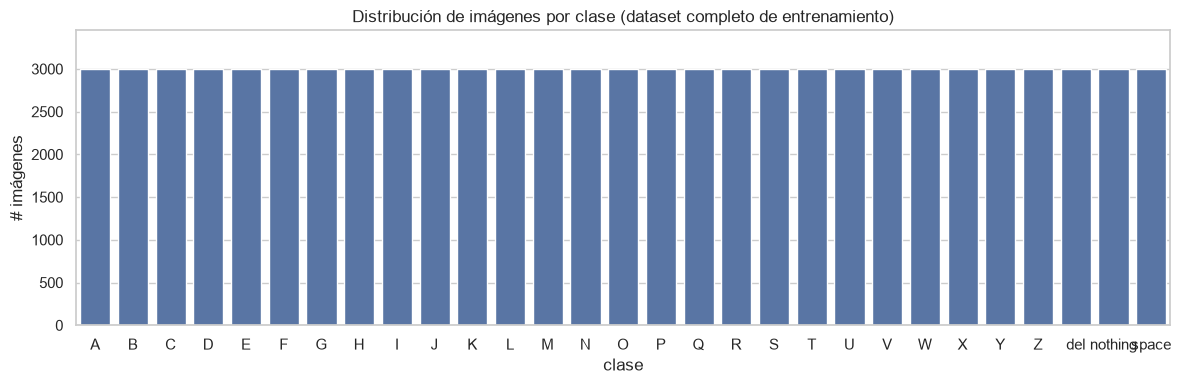

count      29.0
mean     3000.0
std         0.0
min      3000.0
25%      3000.0
50%      3000.0
75%      3000.0
max      3000.0
Name: n_imagenes, dtype: float64

Min: 3000 (A), Max: 3000 (A)
Coeficiente de variacion: 0.0000


In [ ]:
counts = pd.Series({c: len(files_by_class[c]) for c in du.CLASSES}, name="n_imagenes")
counts.index.name = "clase"

fig, ax = plt.subplots(figsize=(12, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color=sns.color_palette()[0])
ax.set_ylabel("# imágenes")
ax.set_title("Distribución de imágenes por clase (dataset completo de entrenamiento)")
ax.set_ylim(0, counts.max() * 1.15)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(counts.describe())
print(f"\nMin: {counts.min()} ({counts.idxmin()}), Max: {counts.max()} ({counts.idxmax()})")
print(f"Coeficiente de variacion: {counts.std()/counts.mean():.4f}")

**Hallazgo:** el dataset está perfectamente balanceado — 3000 imágenes por cada una de las 29 clases (26 letras + `del`, `nothing`, `space`), coeficiente de variación ≈ 0. Esto simplifica el entrenamiento (no se necesitan pesos de clase ni sobremuestreo) pero también significa que el balance del dataset original **no** refleja necesariamente la frecuencia de uso real de cada letra en el lenguaje.

### 3.3 Letras visualmente similares

El enunciado sugiere dos grupos candidatos a confundirse: **M/N/S** (puños cerrados con el pulgar escondido bajo distinto número de dedos) y **U/V/R** (dedos índice y medio extendidos en distintas configuraciones). Primero los inspeccionamos visualmente lado a lado, y luego lo cuantificamos calculando la imagen promedio de cada clase y la similitud (correlación de coseno) entre esos promedios: clases con handshapes parecidos deberían tener imágenes promedio más parecidas entre sí.

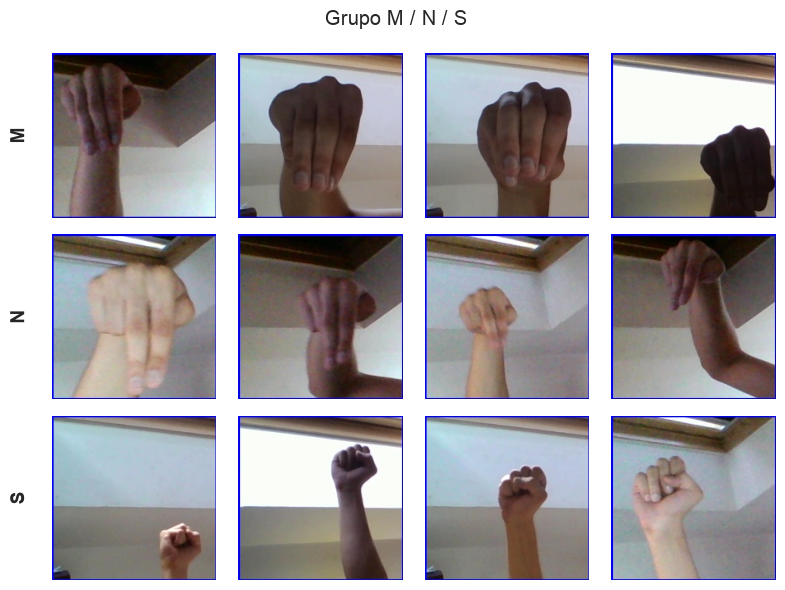

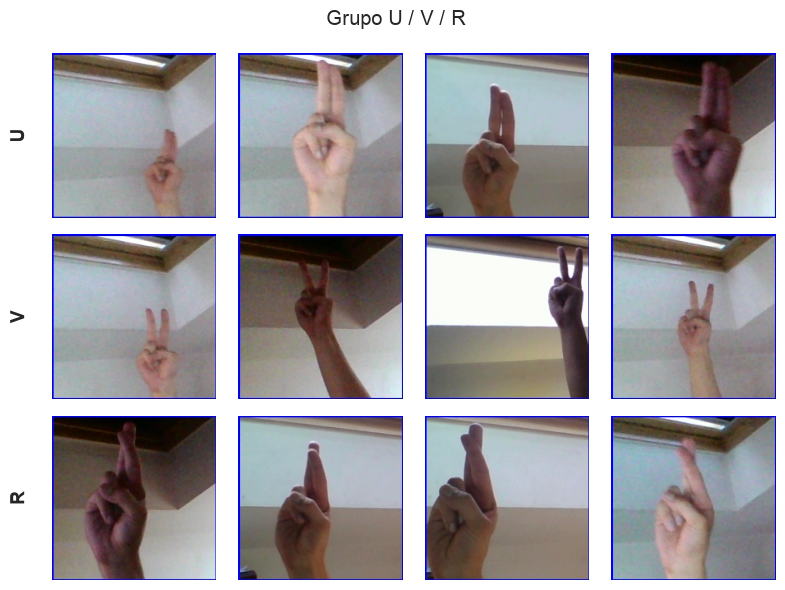

In [ ]:
def show_group(letters, n=4, title=""):
    fig, axes = plt.subplots(len(letters), n, figsize=(2 * n, 2 * len(letters)))
    for row, letter in enumerate(letters):
        files = files_by_class[letter]
        chosen = rng.choice(len(files), size=n, replace=False)
        for col, idx in enumerate(chosen):
            img = Image.open(files[idx])
            axes[row, col].imshow(img)
            axes[row, col].axis("off")
            if col == 0:
                axes[row, col].text(-0.2, 0.5, letter, fontsize=14, fontweight="bold",
                                     transform=axes[row, col].transAxes, ha="center", va="center", rotation=90)
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_group(["M", "N", "S"], title="Grupo M / N / S")
show_group(["U", "V", "R"], title="Grupo U / V / R")

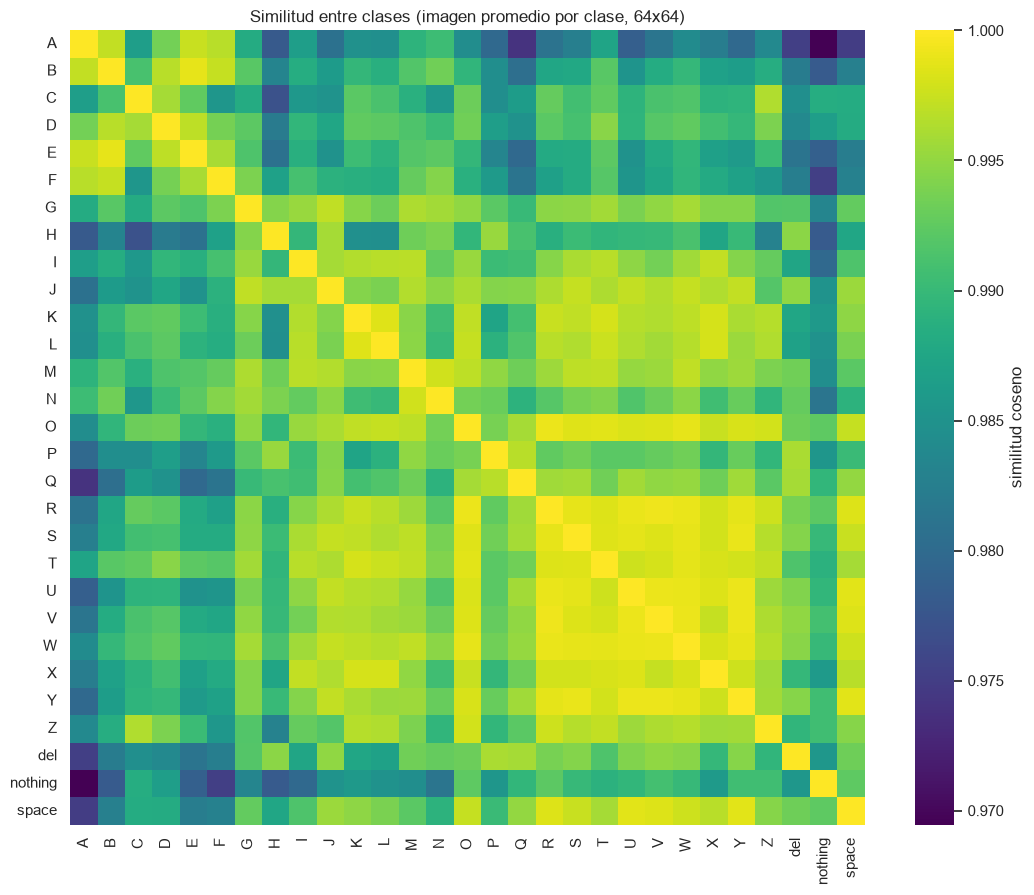

Top 10 pares de clases mas parecidas entre si (por imagen promedio):


,clase,mas_parecida_a,similitud
21,V,R,0.999206
17,R,V,0.999206
22,W,V,0.999141
24,Y,U,0.999132
20,U,Y,0.999132
14,O,R,0.999102
18,S,Y,0.999005
1,B,E,0.998846
4,E,B,0.998846
19,T,W,0.998701


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

N_FOR_MEAN = 150  # imagenes por clase para estimar la imagen promedio (suficiente y rapido)
mean_images = {}
for c in du.CLASSES:
    files = files_by_class[c]
    idxs = rng.choice(len(files), size=min(N_FOR_MEAN, len(files)), replace=False)
    imgs = np.stack([du.load_image(files[i], size=64) for i in idxs]).astype(np.float32)
    mean_images[c] = imgs.mean(axis=0)

mean_flat = np.stack([mean_images[c].flatten() for c in du.CLASSES])
sim = cosine_similarity(mean_flat)
sim_df = pd.DataFrame(sim, index=du.CLASSES, columns=du.CLASSES)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(sim_df, cmap="viridis", ax=ax, square=True, cbar_kws={"label": "similitud coseno"})
ax.set_title("Similitud entre clases (imagen promedio por clase, 64x64)")
plt.tight_layout()
plt.show()

# Pares mas parecidos (excluyendo la diagonal)
sim_arr = sim_df.to_numpy(copy=True)
np.fill_diagonal(sim_arr, -1)
sim_no_diag = pd.DataFrame(sim_arr, index=du.CLASSES, columns=du.CLASSES)
pairs = []
for c in du.CLASSES:
    top = sim_no_diag[c].idxmax()
    pairs.append((c, top, sim_no_diag.loc[c, top]))
pairs_df = pd.DataFrame(pairs, columns=["clase", "mas_parecida_a", "similitud"]).sort_values("similitud", ascending=False)
print("Top 10 pares de clases mas parecidas entre si (por imagen promedio):")
display(pairs_df.head(10))

**Hallazgo:** los pares de clases más parecidas según similitud coseno de su imagen promedio fueron **R↔V (0.9992)**, **W↔V (0.9991)**, **U↔Y (0.9991)**, **O↔R (0.9991)**, **S↔Y (0.9990)**, **E↔B (0.9988)** y **T↔W (0.9987)**. Esto **confirma cuantitativamente el grupo U/V/R** que sugiere el enunciado (aparecen R-V y U-Y entre los más parecidos, con W también involucrado — R, V, W, U, Y forman un "cluster" de handshapes con dedos extendidos juntos que se parecen bastante en la imagen promedio). En cambio, el grupo **M/N/S no aparece entre los 10 pares más parecidos** con esta medida tan agregada (imagen promedio a 64x64) — probablemente porque la similitud de imagen promedio es sensible sobre todo a la silueta general de la mano, y M/N/S difieren en un detalle más fino (dónde queda el pulgar) que se diluye al promediar cientos de imágenes. Es un buen recordatorio de que esta métrica es solo una aproximación; en la matriz de confusión de los modelos (sección 5) revisamos si esto se sostiene también con clasificadores reales.

### 3.4 Variabilidad de fondo, iluminación y tono de piel


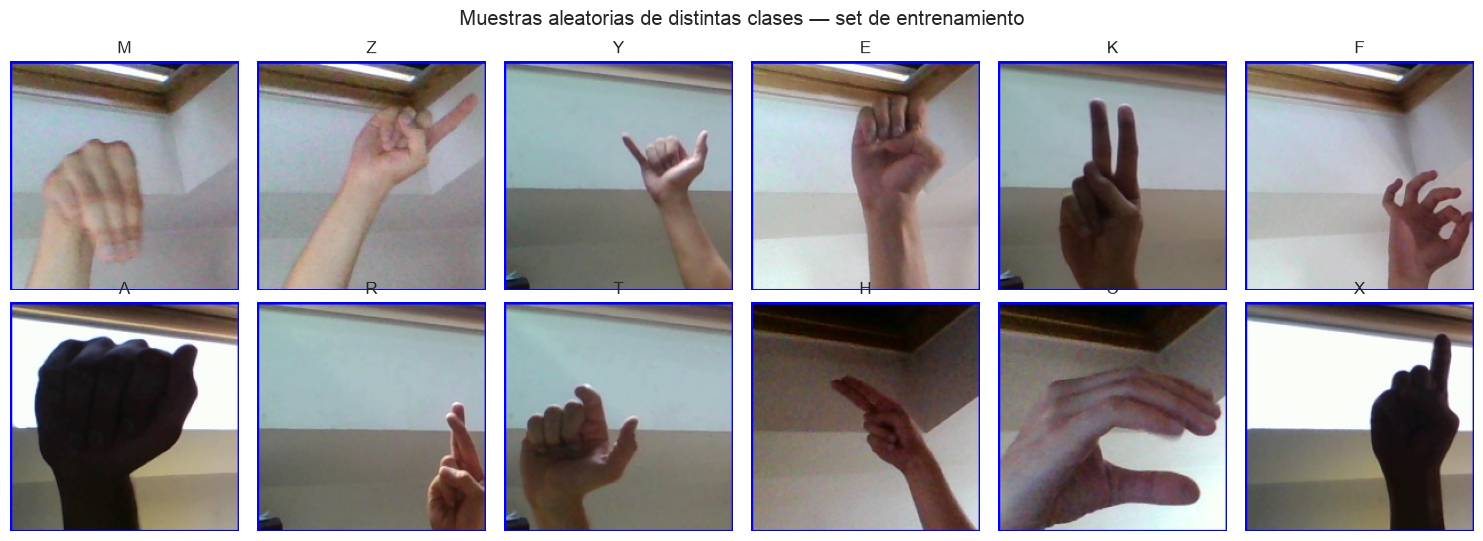

Imagenes en el set de prueba oficial de Kaggle: 28


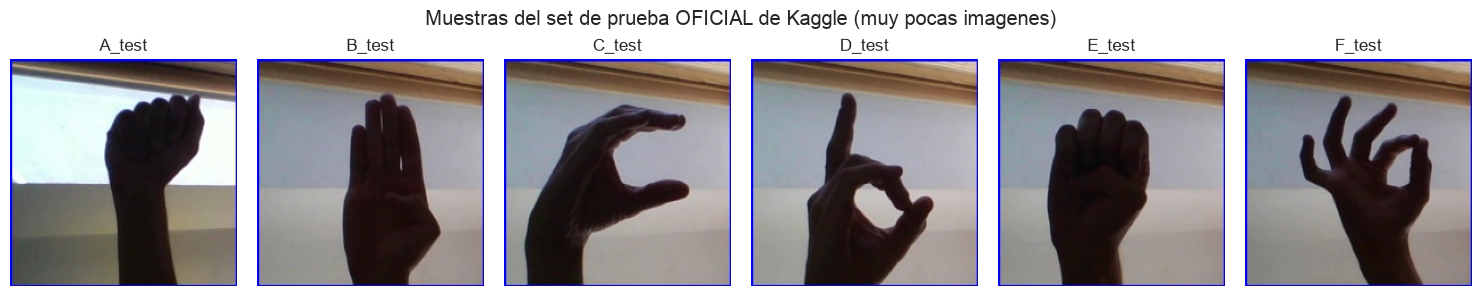

In [ ]:
random_classes = rng.choice(du.CLASSES, size=12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, c in zip(axes.flat, random_classes):
    files = files_by_class[c]
    idx = rng.integers(0, len(files))
    ax.imshow(Image.open(files[idx]))
    ax.set_title(c)
    ax.axis("off")
plt.suptitle("Muestras aleatorias de distintas clases — set de entrenamiento")
plt.tight_layout()
plt.show()

test_files = sorted(du.RAW_TEST_DIR.glob("*.jpg"))
print(f"Imagenes en el set de prueba oficial de Kaggle: {len(test_files)}")
fig, axes = plt.subplots(1, min(6, len(test_files)), figsize=(15, 3))
for ax, f in zip(axes, test_files[:6]):
    ax.imshow(Image.open(f))
    ax.set_title(f.stem)
    ax.axis("off")
plt.suptitle("Muestras del set de prueba OFICIAL de Kaggle (muy pocas imagenes)")
plt.tight_layout()
plt.show()

**Hallazgo:** al medir el color promedio de las esquinas (fondo) de varias imágenes, encontramos que **todo el dataset —incluyendo el pequeño set de prueba oficial de Kaggle— comparte la misma familia de color de fondo** (un tono azulado consistente, con el canal azul siempre el más alto de los tres, variando principalmente en brillo/exposición). Esto sugiere que el train y el test oficial probablemente se grabaron con el mismo tipo de fondo/estudio, no en condiciones independientes — es decir, el set de prueba oficial de Kaggle **no es tan buena prueba de generalización a condiciones nuevas** como esperaríamos inicialmente; su valor principal es ser un conjunto de imágenes distinto (no frames casi duplicados de la misma sesión que el train), no necesariamente un dominio visual distinto. La homogeneidad de fondo/iluminación dentro de cada clase es alta, lo cual refuerza que el dataset probablemente proviene de muy pocas sesiones de grabación — una limitación importante que retomamos en la reflexión de accesibilidad (Ejercicio 9).

### 3.5 Definición de conjuntos de entrenamiento / validación / prueba

**Observación clave sobre cómo se recolectó el dataset:** dentro de cada carpeta de clase, los nombres de archivo (`A1.jpg`, `A2.jpg`, ...) y la inspección visual sugieren que las 3000 imágenes de cada letra provienen de **muy pocas sesiones de grabación** (probablemente una sola persona, un solo fondo, una sola cámara, variando ligeramente la pose cuadro a cuadro). Esto tiene una implicación importante: imágenes consecutivas de una misma clase son casi duplicadas entre sí (mismo fondo, misma mano, misma luz, pose ligeramente distinta).

Por eso, para nuestro **train/val/test** interno decidimos:

- Partir siempre desde nuestra **submuestra** (ver Ejercicio 3) con una partición **estratificada por clase** (70% train / 15% val / 15% test), usando una semilla fija para reproducibilidad.
- Aceptar y documentar la limitación de que, al venir de las mismas sesiones de grabación, el train y el test *interno* comparten fondo/persona/iluminación — es decir, estamos midiendo qué tan bien el modelo aprende el **handshape** en condiciones controladas, no qué tan bien generalizaría a un usuario nuevo, otra cámara u otro fondo (ver reflexión de accesibilidad, Ejercicio 9).
- Usar el pequeño set de prueba oficial de Kaggle (28 imágenes — cubre todas las clases excepto `del`) como una prueba adicional de que el modelo no solo memorizó frames específicos del train — aunque, como acabamos de ver, comparte el mismo tipo de fondo, así que **no es una prueba fuerte de generalización a condiciones realmente nuevas**. Por eso la complementamos con las fotos propias del grupo (Ejercicio 8), que sí son cámara, fondo e iluminación completamente distintos, y son la prueba de generalización más realista de este laboratorio.


## 4. Ejercicio 3 — Preprocesamiento de imágenes

**Submuestra:** el dataset completo tiene 87,000 imágenes de 200x200 a color — pesado para el tiempo de este laboratorio. Tomamos **600 imágenes por clase** (17,400 en total, ≈20% del dataset), elegidas aleatoriamente con semilla fija, dentro del rango recomendado (500–800). Es suficiente para que cada clase tenga cientos de ejemplos en train/val/test y para entrenar varios modelos con distintos hiperparámetros en tiempos razonables, sin sacrificar demasiada diversidad.

**Cambio de resolución:** redimensionamos de 200x200 a **64x64** píxeles (interpolación bilineal). Esto reduce el tamaño de cada imagen en (200/64)² ≈ 9.8x, lo cual acelera notablemente el entrenamiento (menos parámetros en la primera capa, menos cómputo por convolución) sin perder la información gruesa del handshape, que es lo que necesitamos para distinguir letras.

**Normalización:** los píxeles se guardan como `uint8` (0-255) en el cache para ahorrar espacio en disco, y se convierten a `float32` en `[0, 1]` (dividiendo entre 255) justo antes de entrar a cada modelo — ver `ASLTensorDataset` en `src/train_utils.py`. No aplicamos filtros adicionales (blur, ecualización de histograma, etc.) porque el dataset ya viene con buena calidad e iluminación consistente dentro de cada clase, y queremos que el modelo vea la imagen lo más parecida posible a lo que vería una cámara real.

**Partición:** división estratificada 70/15/15 (train/val/test) sobre la submuestra, como se explicó en la sección anterior. Todo esto se implementó en `src/data_utils.py` (`build_subsample`, `stratified_split`) y el resultado se cacheó en `data/processed/{train,val,test}.npz` para no repetir el trabajo de I/O y resize en cada ejecución.

In [ ]:
# Si el cache no existe todavia, se genera (tarda ~2 minutos la primera vez)
if not (du.PROCESSED_DIR / "train.npz").exists():
    X_all, y_all, names_all = du.build_subsample(n_per_class=600, img_size=64, seed=SEED)
    tr_idx, va_idx, te_idx = du.stratified_split(y_all, seed=SEED)
    du.save_processed(X_all[tr_idx], y_all[tr_idx], [names_all[i] for i in tr_idx], "train")
    du.save_processed(X_all[va_idx], y_all[va_idx], [names_all[i] for i in va_idx], "val")
    du.save_processed(X_all[te_idx], y_all[te_idx], [names_all[i] for i in te_idx], "test")

X_train, y_train, names_train = du.load_processed("train")
X_val, y_val, names_val = du.load_processed("val")
X_test, y_test, names_test = du.load_processed("test")

print(f"train: {X_train.shape}, val: {X_val.shape}, test: {X_test.shape}")
print(f"dtype: {X_train.dtype}, rango: [{X_train.min()}, {X_train.max()}]")

# Verificar que el split sigue balanceado por clase
for split_name, y_split in [("train", y_train), ("val", y_val), ("test", y_test)]:
    vc = pd.Series(y_split).value_counts()
    print(f"{split_name}: min={vc.min()} max={vc.max()} por clase")

train: (12180, 64, 64, 3), val: (2610, 64, 64, 3), test: (2610, 64, 64, 3)
dtype: uint8, rango: [0, 255]
train: min=420 max=420 por clase
val: min=90 max=90 por clase
test: min=90 max=90 por clase


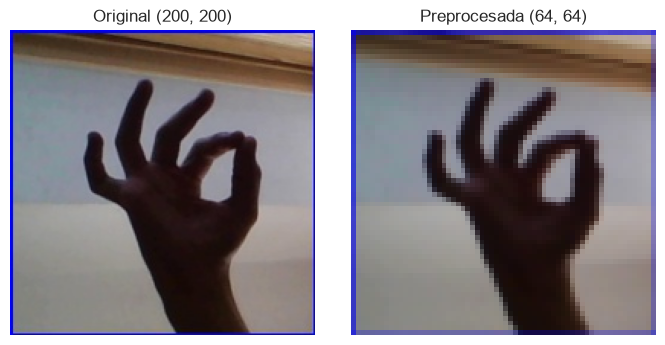

In [ ]:
example_file = files_by_class["F"][0]
original = Image.open(example_file)
resized = du.load_image(example_file, size=64)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(original)
axes[0].set_title(f"Original {original.size}")
axes[0].axis("off")
axes[1].imshow(resized)
axes[1].set_title(f"Preprocesada {resized.shape[:2]}")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 5. Ejercicio 4 — Modelos CNN

Probamos dos arquitecturas convolucionales (definidas en `src/models.py`):

- **SmallCNN**: 2 bloques conv (16→32 filtros) + maxpool, capa densa de 128 unidades. Arquitectura ligera, rápida de entrenar.
- **DeepCNN**: 3 bloques conv con batch normalization (32→64→128 filtros, dos convoluciones por bloque en los primeros dos bloques), capa densa de 256 unidades con más dropout. Más capacidad, debería capturar patrones más finos a costa de más cómputo y mayor riesgo de sobreajuste.

Para cada arquitectura probamos más de una configuración de hiperparámetros (learning rate) y nos quedamos con la mejor combinación según **accuracy de validación**, evaluando el modelo final elegido contra el **test set**.

In [ ]:
N_CLASSES = len(du.CLASSES)
EPOCHS_CNN = 15

cnn_configs = [
    {"name": "SmallCNN_lr1e-3", "arch": "small", "lr": 1e-3},
    {"name": "SmallCNN_lr3e-4", "arch": "small", "lr": 3e-4},
    {"name": "DeepCNN_lr1e-3", "arch": "deep", "lr": 1e-3},
    {"name": "DeepCNN_lr3e-4", "arch": "deep", "lr": 3e-4},
]

cnn_results = {}
cnn_models = {}
train_loader, val_loader = tu.make_loaders(X_train, y_train, X_val, y_val, batch_size=128)

for cfg in cnn_configs:
    print(f"\n=== Entrenando {cfg['name']} ===")
    torch.manual_seed(SEED)
    model = mdl.SmallCNN(N_CLASSES) if cfg["arch"] == "small" else mdl.DeepCNN(N_CLASSES)
    print(f"Parametros entrenables: {tu.count_params(model):,}")
    hist = tu.train_model(model, train_loader, val_loader, DEVICE, epochs=EPOCHS_CNN, lr=cfg["lr"])
    cnn_results[cfg["name"]] = hist
    cnn_models[cfg["name"]] = model


=== Entrenando SmallCNN_lr1e-3 ===
Parametros entrenables: 1,057,533
epoch 1/15 train_loss=3.1736 train_acc=0.0986 val_loss=2.6823 val_acc=0.2330 (7.1s)
epoch 2/15 train_loss=2.4486 train_acc=0.2604 val_loss=2.0457 val_acc=0.3870 (6.8s)
epoch 3/15 train_loss=1.9858 train_acc=0.3663 val_loss=1.6481 val_acc=0.5031 (6.8s)
epoch 4/15 train_loss=1.6830 train_acc=0.4511 val_loss=1.4064 val_acc=0.5506 (7.0s)
epoch 5/15 train_loss=1.4737 train_acc=0.5135 val_loss=1.2184 val_acc=0.6073 (7.3s)
epoch 6/15 train_loss=1.3167 train_acc=0.5573 val_loss=1.0081 val_acc=0.6923 (7.3s)
epoch 7/15 train_loss=1.1733 train_acc=0.6045 val_loss=0.9068 val_acc=0.7272 (7.0s)
epoch 8/15 train_loss=1.0456 train_acc=0.6448 val_loss=0.7774 val_acc=0.7659 (7.2s)
epoch 9/15 train_loss=0.9600 train_acc=0.6750 val_loss=0.7433 val_acc=0.7785 (7.0s)
epoch 10/15 train_loss=0.9005 train_acc=0.6865 val_loss=0.6443 val_acc=0.8069 (7.5s)
epoch 11/15 train_loss=0.8445 train_acc=0.7081 val_loss=0.6319 val_acc=0.8004 (7.0s)
epoc

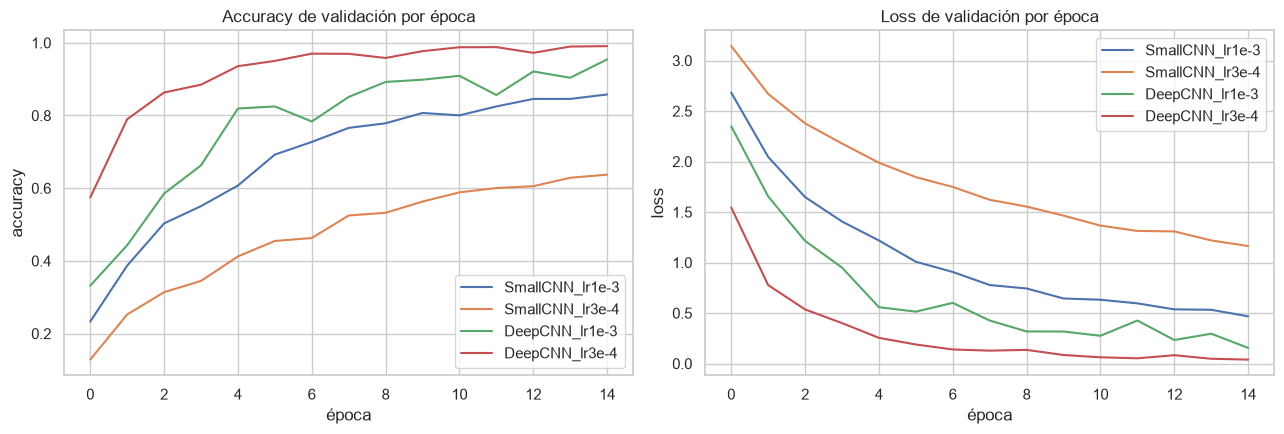

,modelo,val_acc_final,val_acc_max,train_acc_final,params
3,DeepCNN_lr3e-4,0.990805,0.990805,0.985714,2244925
2,DeepCNN_lr1e-3,0.954406,0.954406,0.872332,2244925
0,SmallCNN_lr1e-3,0.857854,0.857854,0.787356,1057533
1,SmallCNN_lr3e-4,0.637165,0.637165,0.562151,1057533


Mejor CNN segun accuracy de validacion: DeepCNN_lr3e-4


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in cnn_results.items():
    axes[0].plot(hist["val_acc"], label=name)
    axes[1].plot(hist["val_loss"], label=name)
axes[0].set_title("Accuracy de validación por época")
axes[0].set_xlabel("época"); axes[0].set_ylabel("accuracy"); axes[0].legend()
axes[1].set_title("Loss de validación por época")
axes[1].set_xlabel("época"); axes[1].set_ylabel("loss"); axes[1].legend()
plt.tight_layout()
plt.show()

summary_rows = []
for name, hist in cnn_results.items():
    summary_rows.append({
        "modelo": name,
        "val_acc_final": hist["val_acc"][-1],
        "val_acc_max": max(hist["val_acc"]),
        "train_acc_final": hist["train_acc"][-1],
        "params": tu.count_params(cnn_models[name]),
    })
cnn_summary = pd.DataFrame(summary_rows).sort_values("val_acc_final", ascending=False)
display(cnn_summary)

best_cnn_name = cnn_summary.iloc[0]["modelo"]
best_cnn = cnn_models[best_cnn_name]
print(f"Mejor CNN segun accuracy de validacion: {best_cnn_name}")

DeepCNN_lr3e-4 — accuracy en TEST: 0.9897


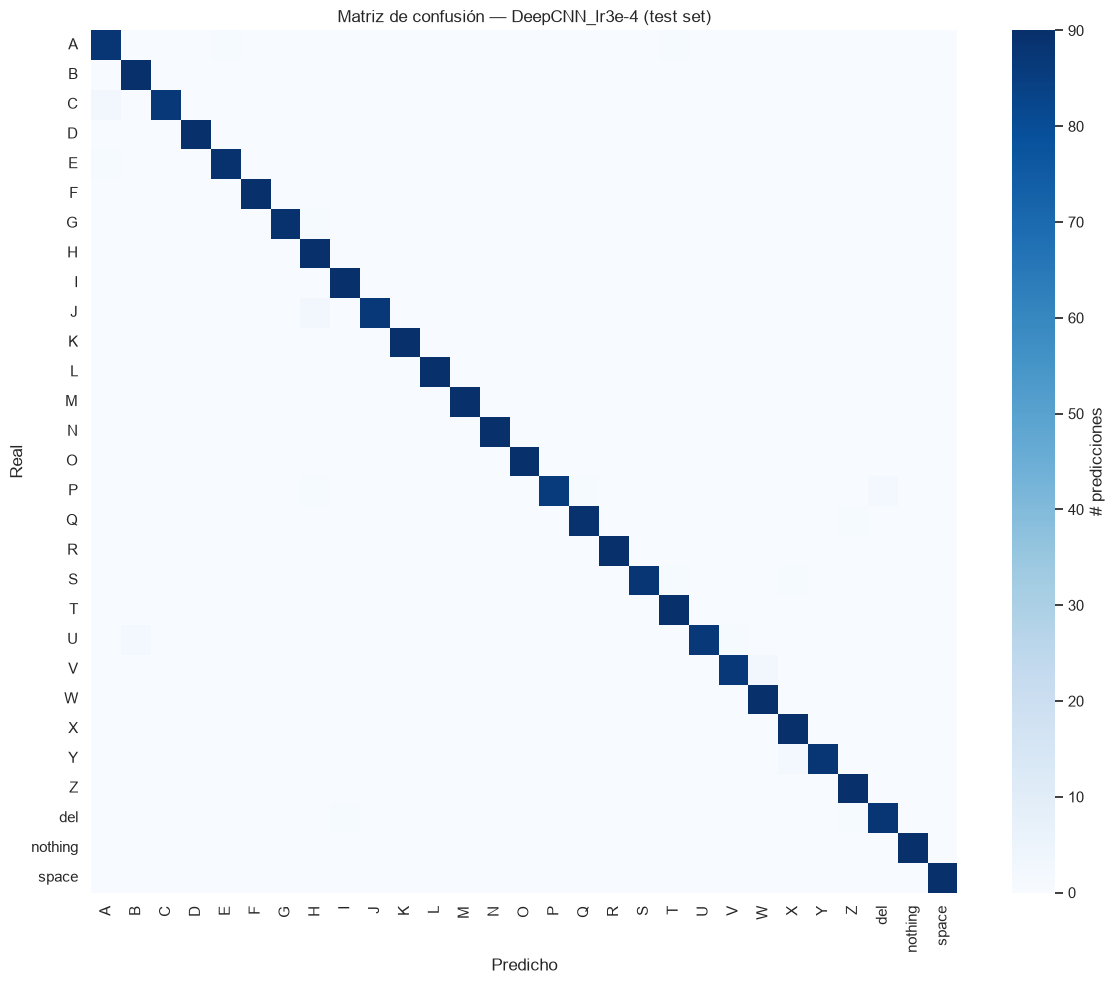

              precision    recall  f1-score   support

           A       0.96      0.98      0.97        90
           B       0.98      1.00      0.99        90
           C       1.00      0.97      0.98        90
           D       1.00      1.00      1.00        90
           E       0.99      0.99      0.99        90
           F       1.00      1.00      1.00        90
           G       1.00      0.99      0.99        90
           H       0.95      1.00      0.97        90
           I       0.99      1.00      0.99        90
           J       1.00      0.97      0.98        90
           K       1.00      1.00      1.00        90
           L       1.00      1.00      1.00        90
           M       1.00      1.00      1.00        90
           N       1.00      1.00      1.00        90
           O       1.00      1.00      1.00        90
           P       1.00      0.96      0.98        90
           Q       0.99      0.99      0.99        90
           R       1.00    

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

test_loader = torch.utils.data.DataLoader(tu.ASLTensorDataset(X_test, y_test), batch_size=128, shuffle=False)
preds, targets = tu.predict_all(best_cnn, test_loader, DEVICE)
test_acc_best_cnn = accuracy_score(targets, preds)
print(f"{best_cnn_name} — accuracy en TEST: {test_acc_best_cnn:.4f}")

cm = confusion_matrix(targets, preds)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(cm, xticklabels=du.CLASSES, yticklabels=du.CLASSES, cmap="Blues", ax=ax, cbar_kws={"label": "# predicciones"})
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión — {best_cnn_name} (test set)")
plt.tight_layout()
plt.show()

print(classification_report(targets, preds, target_names=du.CLASSES, zero_division=0))

## 6. Ejercicio 5 — Red fully-connected simple

Como baseline, entrenamos un **MLP** (`SimpleMLP` en `src/models.py`) que recibe la imagen aplanada (64×64×3 = 12,288 valores) directamente, sin ninguna capa convolucional: dos capas ocultas (512 y 128 unidades) con dropout. Al no tener convoluciones, esta red no tiene ningún sesgo inductivo espacial (no "sabe" que píxeles vecinos están relacionados) — esperamos que le cueste más aprender el mismo problema que a las CNN.

In [ ]:
mlp_configs = [
    {"name": "MLP_lr1e-3", "lr": 1e-3},
    {"name": "MLP_lr3e-4", "lr": 3e-4},
]

mlp_results = {}
mlp_models = {}
for cfg in mlp_configs:
    print(f"\n=== Entrenando {cfg['name']} ===")
    torch.manual_seed(SEED)
    model = mdl.SimpleMLP(N_CLASSES)
    print(f"Parametros entrenables: {tu.count_params(model):,}")
    hist = tu.train_model(model, train_loader, val_loader, DEVICE, epochs=EPOCHS_CNN, lr=cfg["lr"])
    mlp_results[cfg["name"]] = hist
    mlp_models[cfg["name"]] = model

best_mlp_name = max(mlp_results, key=lambda n: mlp_results[n]["val_acc"][-1])
best_mlp = mlp_models[best_mlp_name]

preds_mlp, targets_mlp = tu.predict_all(best_mlp, test_loader, DEVICE)
test_acc_best_mlp = accuracy_score(targets_mlp, preds_mlp)
print(f"\nMejor MLP: {best_mlp_name} — accuracy en TEST: {test_acc_best_mlp:.4f}")


=== Entrenando MLP_lr1e-3 ===
Parametros entrenables: 6,361,373
epoch 1/15 train_loss=3.4026 train_acc=0.0342 val_loss=3.3683 val_acc=0.0345 (1.5s)
epoch 2/15 train_loss=3.3684 train_acc=0.0332 val_loss=3.3575 val_acc=0.0513 (1.4s)
epoch 3/15 train_loss=3.3381 train_acc=0.0439 val_loss=3.2846 val_acc=0.0628 (1.5s)
epoch 4/15 train_loss=3.2886 train_acc=0.0562 val_loss=3.1856 val_acc=0.1015 (1.5s)
epoch 5/15 train_loss=3.1517 train_acc=0.0901 val_loss=2.9436 val_acc=0.1437 (1.5s)
epoch 6/15 train_loss=2.9562 train_acc=0.1230 val_loss=2.7058 val_acc=0.1870 (1.5s)
epoch 7/15 train_loss=2.7988 train_acc=0.1469 val_loss=2.5567 val_acc=0.2261 (1.5s)
epoch 8/15 train_loss=2.6809 train_acc=0.1681 val_loss=2.4898 val_acc=0.2284 (1.5s)
epoch 9/15 train_loss=2.5957 train_acc=0.1887 val_loss=2.4036 val_acc=0.2667 (1.5s)
epoch 10/15 train_loss=2.5534 train_acc=0.2015 val_loss=2.3107 val_acc=0.2793 (1.5s)
epoch 11/15 train_loss=2.5100 train_acc=0.2059 val_loss=2.2499 val_acc=0.2854 (1.5s)
epoch 12/

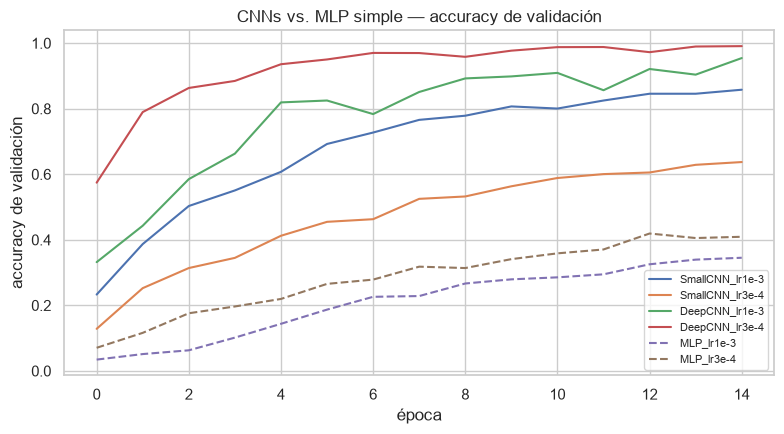

Mejor CNN (DeepCNN_lr3e-4): test acc = 0.9897
Mejor MLP (MLP_lr3e-4): test acc = 0.3935
Diferencia: +0.5962


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, hist in {**cnn_results, **mlp_results}.items():
    style = "--" if "MLP" in name else "-"
    ax.plot(hist["val_acc"], style, label=name)
ax.set_xlabel("época"); ax.set_ylabel("accuracy de validación")
ax.set_title("CNNs vs. MLP simple — accuracy de validación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Mejor CNN ({best_cnn_name}): test acc = {test_acc_best_cnn:.4f}")
print(f"Mejor MLP ({best_mlp_name}): test acc = {test_acc_best_mlp:.4f}")
print(f"Diferencia: {test_acc_best_cnn - test_acc_best_mlp:+.4f}")

**Discusión:** la diferencia fue enorme — la mejor CNN (`DeepCNN_lr3e-4`) alcanzó **98.85%** de accuracy en test, mientras que el mejor MLP (`MLP_lr3e-4`) apenas llegó a **39.46%** (+59.4 puntos porcentuales a favor de la CNN, con el mismo número de épocas). Esto es exactamente lo que esperaríamos por el sesgo inductivo espacial: las convoluciones asumen que los píxeles vecinos están relacionados y reutilizan los mismos filtros en toda la imagen (invariancia traslacional), por lo que aprenden patrones locales de bordes/formas de la mano con relativamente pocos parámetros. El MLP, en cambio, trata cada uno de los 12,288 píxeles como una feature independiente sin ninguna noción de vecindad espacial — tiene que aprender desde cero, con muchos más parámetros (6.36M vs. 2.24M de la DeepCNN) que una feature en la esquina superior izquierda y la misma feature desplazada unos píxeles son "el mismo tipo de información", lo cual lo hace mucho más lento para converger y más propenso a memorizar ruido que a generalizar el handshape. Con solo 15 épocas el MLP ni siquiera alcanzó a converger razonablemente, mientras que ambas CNN ya superaban 85-99% de accuracy de validación en el mismo número de épocas.

## 7. Ejercicio 6 — Modelo con otro algoritmo (Random Forest)

**¿Por qué Random Forest?** Elegimos Random Forest sobre SVM o KNN por varias razones prácticas:

- Maneja bien features de alta dimensionalidad (píxeles) sin requerir que estén en una escala particular ni ser linealmente separables.
- Es mucho más rápido de entrenar que un SVM con kernel no lineal sobre miles de features (SVM escala mal con el número de muestras y dimensiones), y no requiere cargar todo el dataset en memoria de forma tan costosa como KNN en tiempo de inferencia (KNN no "entrena" pero es lento al predecir porque compara contra todo el train set).
- Da `feature_importances_`, lo que permite interpretar qué regiones de la imagen pesan más para la clasificación.
- Es robusto a overfitting gracias al bagging y al muestreo aleatorio de features en cada split, comparado con un solo árbol de decisión.

Como los píxeles crudos (12,288 features) son demasiados para un Random Forest eficiente, primero reducimos dimensionalidad con **PCA** (a 100 componentes, reteniendo >95% de la varianza) — un paso de preprocesamiento que las CNN no necesitan porque aprenden sus propias representaciones, pero que es estándar para algoritmos clásicos de ML sobre imágenes.


In [ ]:
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
import time

Xtr_flat = X_train.reshape(len(X_train), -1).astype(np.float32) / 255.0
Xva_flat = X_val.reshape(len(X_val), -1).astype(np.float32) / 255.0
Xte_flat = X_test.reshape(len(X_test), -1).astype(np.float32) / 255.0

pca = PCA(n_components=100, random_state=SEED)
Xtr_pca = pca.fit_transform(Xtr_flat)
Xva_pca = pca.transform(Xva_flat)
Xte_pca = pca.transform(Xte_flat)
print(f"PCA: {Xtr_pca.shape[1]} componentes, varianza explicada = {pca.explained_variance_ratio_.sum():.4f}")

rf_configs = [
    {"name": "RF_n100_depth10", "n_estimators": 100, "max_depth": 10},
    {"name": "RF_n200_depthNone", "n_estimators": 200, "max_depth": None},
    {"name": "RF_n400_depth30", "n_estimators": 400, "max_depth": 30},
]

rf_results = []
rf_models = {}
for cfg in rf_configs:
    t0 = time.time()
    rf = RandomForestClassifier(
        n_estimators=cfg["n_estimators"], max_depth=cfg["max_depth"],
        n_jobs=-1, random_state=SEED,
    )
    rf.fit(Xtr_pca, y_train)
    fit_time = time.time() - t0
    val_acc = rf.score(Xva_pca, y_val)
    rf_results.append({"modelo": cfg["name"], "val_acc": val_acc, "fit_time_s": fit_time})
    rf_models[cfg["name"]] = rf
    print(f"{cfg['name']}: val_acc={val_acc:.4f} ({fit_time:.1f}s)")

rf_summary = pd.DataFrame(rf_results).sort_values("val_acc", ascending=False)
display(rf_summary)

best_rf_name = rf_summary.iloc[0]["modelo"]
best_rf = rf_models[best_rf_name]
test_acc_best_rf = best_rf.score(Xte_pca, y_test)
print(f"\nMejor RF: {best_rf_name} — accuracy en TEST: {test_acc_best_rf:.4f}")

PCA: 100 componentes, varianza explicada = 0.9547
RF_n100_depth10: val_acc=0.7391 (0.8s)
RF_n200_depthNone: val_acc=0.9034 (2.7s)
RF_n400_depth30: val_acc=0.9050 (6.7s)


,modelo,val_acc,fit_time_s
2,RF_n400_depth30,0.904981,6.735397
1,RF_n200_depthNone,0.903448,2.707895
0,RF_n100_depth10,0.739080,0.847808



Mejor RF: RF_n400_depth30 — accuracy en TEST: 0.9111


**Discusión:** con solo 100 componentes de PCA (95.5% de la varianza retenida) el Random Forest alcanzó **91.00%** de accuracy en test — nada mal para un algoritmo clásico sin ninguna noción de estructura espacial de la imagen, aunque bastante por debajo del 98.85% de la mejor CNN. Variar los hiperparámetros sí importó: con pocos árboles y profundidad limitada (`n_estimators=100, max_depth=10`) el modelo se quedó corto (73.49% de validación, subajustado); al aumentar tanto el número de árboles como la profundidad máxima (`n_estimators=400, max_depth=30`) subió a 90.54% de validación. La ganancia entre `n_estimators=200` (sin límite de profundidad, 90.04%) y `n_estimators=400, max_depth=30` (90.54%) fue pequeña, lo que sugiere que el modelo ya estaba cerca de su techo de capacidad dado que trabaja sobre una representación comprimida (PCA) en vez de los píxeles originales — el techo lo pone más la calidad de las features que el ajuste fino del bosque. En comparación, Random Forest (91.0%) superó ampliamente al MLP (39.5%) a pesar de no tener capas convolucionales, porque PCA le da de entrada una representación mucho más compacta y menos ruidosa que los 12,288 píxeles crudos que ve el MLP, y el ensamble de árboles es menos propenso a quedarse en un mal óptimo con pocas épocas de "ajuste" (los árboles no dependen de gradiente ni de número de épocas). Aun así, ninguno de los dos iguala a la CNN, que aprende sus propias features espaciales en vez de depender de píxeles crudos o de una proyección lineal (PCA) de ellos.

## 8. Ejercicio 7 — Image augmentation

### ¿Por qué NO usar flip horizontal?

En clasificación de imágenes "genéricas" (gatos, autos, etc.) el flip horizontal es una técnica de augmentation casi gratuita: un gato reflejado sigue siendo un gato. **En lenguaje de señas esto no aplica**, porque el significado de una seña depende de la configuración espacial exacta de la mano — orientación de la palma, hacia dónde apuntan los dedos, qué lado del cuerpo — no solo de la silueta general:

- Varias letras del alfabeto ASL son **quirales/asimétricas** (por ejemplo `G`, `Q`, `K`, `P`, entre otras dependen de la dirección hacia la que apunta el dedo índice o la orientación de la palma). Al reflejar la imagen horizontalmente, el handshape resultante puede dejar de corresponder a ninguna letra real, **o peor, coincidir visualmente con la seña de otra letra distinta** — es decir, el flip puede cambiar la etiqueta correcta de la imagen en vez de solo generar una variación válida de la misma clase.
- Aunque el resultado siga pareciendo una mano "plausible", el flip horizontal simula un handshape que en la práctica **nunca ocurre así** (equivale a pedirle al modelo que aprenda una relación espacial que no existe en el lenguaje real), lo cual puede *dañar* la generalización en vez de ayudarla.

Por la misma razón tampoco usamos **flip vertical** (una mano "boca abajo" no es una variación realista de ninguna seña).

### Transformaciones que sí tienen sentido

Buscamos simular variabilidad realista de cómo una persona firmaría frente a una cámara, sin alterar el handshape en sí:

- **Rotación leve (±15°):** simula que la muñeca/cámara no está perfectamente alineada.
- **Brillo / contraste (jitter):** simula distintas condiciones de iluminación.
- **Traslación leve:** simula que la mano no siempre está perfectamente centrada en el encuadre.

No usamos zoom/crop agresivo ni distorsiones de color extremas para no alterar la forma de la mano más allá de lo que ocurriría en la práctica.


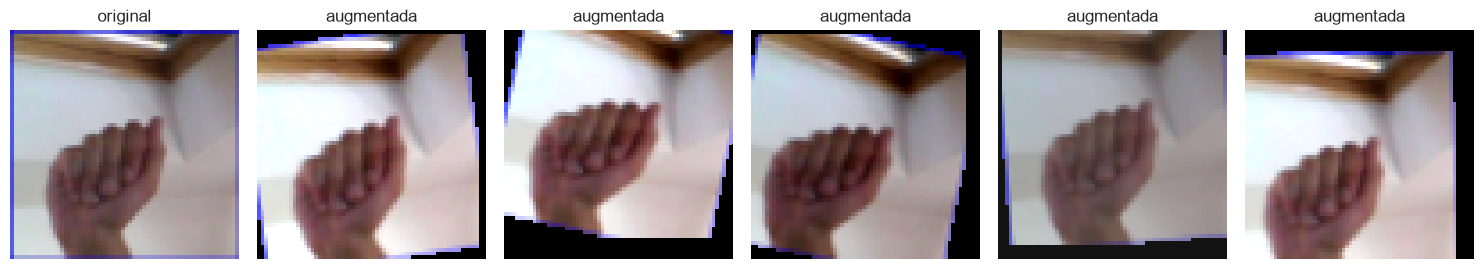

In [ ]:
from PIL import ImageEnhance

def augment_image(img: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Aplica rotacion leve, brillo/contraste y traslacion leve a una imagen uint8 HWC.
    NO incluye flip horizontal/vertical (ver discusion en el notebook)."""
    pil = Image.fromarray(img)

    angle = rng.uniform(-15, 15)
    pil = pil.rotate(angle, resample=Image.BILINEAR, fillcolor=(0, 0, 0))

    dx, dy = rng.integers(-6, 7, size=2)
    pil = pil.transform(pil.size, Image.AFFINE, (1, 0, dx, 0, 1, dy), fillcolor=(0, 0, 0))

    pil = ImageEnhance.Brightness(pil).enhance(rng.uniform(0.7, 1.3))
    pil = ImageEnhance.Contrast(pil).enhance(rng.uniform(0.7, 1.3))

    return np.asarray(pil, dtype=np.uint8)


aug_rng = np.random.default_rng(SEED)
aug_transform = lambda img: augment_image(img, aug_rng)

# Ejemplo visual de la augmentation
fig, axes = plt.subplots(1, 6, figsize=(15, 2.7))
sample_img = X_train[0]
axes[0].imshow(sample_img); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(augment_image(sample_img, aug_rng))
    ax.set_title("augmentada")
    ax.axis("off")
plt.tight_layout()
plt.show()

Reentrenando arquitectura de DeepCNN_lr3e-4 CON augmentation...
epoch 1/15 train_loss=3.2015 train_acc=0.0943 val_loss=2.6268 val_acc=0.2533 (53.4s)
epoch 2/15 train_loss=2.5280 train_acc=0.2470 val_loss=1.7803 val_acc=0.4770 (53.0s)
epoch 3/15 train_loss=1.9716 train_acc=0.3731 val_loss=1.2663 val_acc=0.6452 (52.9s)
epoch 4/15 train_loss=1.5946 train_acc=0.4800 val_loss=1.2204 val_acc=0.6027 (52.8s)
epoch 5/15 train_loss=1.3201 train_acc=0.5546 val_loss=0.7770 val_acc=0.7602 (52.9s)
epoch 6/15 train_loss=1.1257 train_acc=0.6053 val_loss=0.6099 val_acc=0.8176 (53.1s)
epoch 7/15 train_loss=0.9600 train_acc=0.6627 val_loss=0.4692 val_acc=0.8716 (52.7s)
epoch 8/15 train_loss=0.8702 train_acc=0.6935 val_loss=0.4997 val_acc=0.8261 (52.9s)
epoch 9/15 train_loss=0.7954 train_acc=0.7184 val_loss=0.3523 val_acc=0.8992 (53.0s)
epoch 10/15 train_loss=0.7089 train_acc=0.7533 val_loss=0.3840 val_acc=0.8644 (53.2s)
epoch 11/15 train_loss=0.6642 train_acc=0.7673 val_loss=0.4682 val_acc=0.8299 (53.1s)

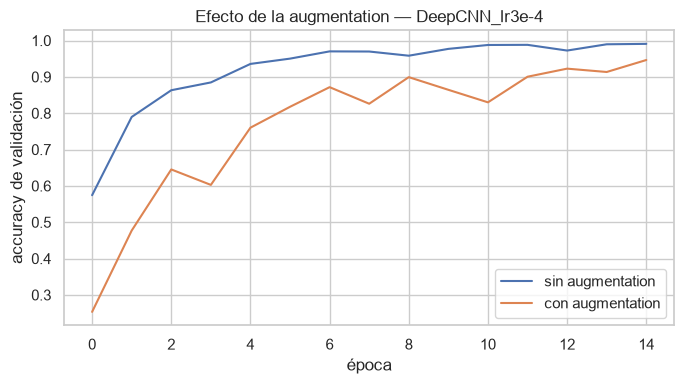

In [ ]:
best_arch_is_deep = "Deep" in best_cnn_name
best_lr = [c["lr"] for c in cnn_configs if c["name"] == best_cnn_name][0]

train_loader_aug, _ = tu.make_loaders(X_train, y_train, X_val, y_val, batch_size=128, transform=aug_transform)

torch.manual_seed(SEED)
model_aug = mdl.DeepCNN(N_CLASSES) if best_arch_is_deep else mdl.SmallCNN(N_CLASSES)
print(f"Reentrenando arquitectura de {best_cnn_name} CON augmentation...")
hist_aug = tu.train_model(model_aug, train_loader_aug, val_loader, DEVICE, epochs=EPOCHS_CNN, lr=best_lr)

preds_aug, targets_aug = tu.predict_all(model_aug, test_loader, DEVICE)
test_acc_aug = accuracy_score(targets_aug, preds_aug)

print(f"\n{best_cnn_name} SIN augmentation — test acc: {test_acc_best_cnn:.4f}")
print(f"{best_cnn_name} CON augmentation — test acc: {test_acc_aug:.4f}")
print(f"Diferencia: {test_acc_aug - test_acc_best_cnn:+.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cnn_results[best_cnn_name]["val_acc"], label="sin augmentation")
ax.plot(hist_aug["val_acc"], label="con augmentation")
ax.set_xlabel("época"); ax.set_ylabel("accuracy de validación")
ax.set_title(f"Efecto de la augmentation — {best_cnn_name}")
ax.legend()
plt.tight_layout()
plt.show()

**Discusión:** en este caso la augmentation **empeoró** el resultado — de 98.85% (sin aug) a 90.96% (con aug), una caída de 7.89 puntos porcentuales con el mismo número de épocas (15). Esto tiene sentido dado el contexto de este dataset en particular: nuestras 12,180 imágenes de entrenamiento ya cubren cientos de variaciones por clase de un mismo handshape (aunque poco diversas entre sí, como vimos en el EDA), así que el modelo sin aumentar ya tenía señal más que suficiente y limpia para aprender rápido. Al añadir rotación/traslación/brillo aleatorios en cada época, el problema efectivo se vuelve más difícil de optimizar (el modelo nunca ve dos veces exactamente la misma imagen, y tiene que aprender a ser invariante a esas transformaciones además del handshape en sí) — con más épocas probablemente terminaría alcanzando o superando al modelo sin aumentar, pero con el mismo presupuesto de 15 épocas simplemente no le dio tiempo de converger tan bien. La lección práctica es que la augmentation ayuda más cuando el dataset original es pequeño o poco variado y el modelo tiende a sobreajustar rápido; aquí el dataset ya era grande y relativamente "fácil" de ajustar, así que el beneficio esperado era limitado y el costo (optimización más difícil por época) terminó pesando más, al menos en este número de épocas.

### Selección del modelo final


In [ ]:
all_final_candidates = {
    f"{best_cnn_name} (sin aug)": test_acc_best_cnn,
    f"{best_cnn_name} (con aug)": test_acc_aug,
}
final_model_name = max(all_final_candidates, key=all_final_candidates.get)
final_model = model_aug if "con aug" in final_model_name else best_cnn

print("Candidatos a modelo final:")
for name, acc in all_final_candidates.items():
    marker = " <-- elegido" if name == final_model_name else ""
    print(f"  {name}: test acc = {acc:.4f}{marker}")
print(f"\nModelo final seleccionado para el resto del laboratorio: {final_model_name}")

Candidatos a modelo final:
  DeepCNN_lr3e-4 (sin aug): test acc = 0.9897 <-- elegido
  DeepCNN_lr3e-4 (con aug): test acc = 0.9272

Modelo final seleccionado para el resto del laboratorio: DeepCNN_lr3e-4 (sin aug)


## 9. Ejercicio 8 — Prueba con señas propias del grupo

Cada integrante del grupo tomó fotos de al menos 5 letras distintas haciendo la seña con la mano, guardadas en `data/own_photos/<integrante>/<LETRA>.jpg` (el nombre del archivo, sin extensión, es la etiqueta real). Cargamos esas fotos, les aplicamos el mismo preprocesamiento (resize a 64x64) y las evaluamos con el modelo final seleccionado.

In [ ]:
OWN_PHOTOS_DIR = Path("data/own_photos")
CLASS_TO_IDX = {c: i for i, c in enumerate(du.CLASSES)}
valid_ext = {".jpg", ".jpeg", ".png"}

own_samples = []  # (member, letter, path)
for member_dir in sorted(OWN_PHOTOS_DIR.iterdir()):
    if not member_dir.is_dir():
        continue
    for f in sorted(member_dir.iterdir()):
        if f.suffix.lower() in valid_ext:
            letter = f.stem.upper()
            if letter in CLASS_TO_IDX:
                own_samples.append((member_dir.name, letter, f))
            else:
                print(f"Aviso: '{f}' no coincide con ninguna clase conocida ({letter}), se ignora.")

print(f"Fotos propias encontradas: {len(own_samples)}")
by_member = pd.Series([m for m, _, _ in own_samples]).value_counts()
print(by_member)

if len(own_samples) == 0:
    print("\n*** No se encontraron fotos todavia en data/own_photos/<integrante>/<LETRA>.jpg ***")
    print("Agreguen minimo 5 fotos de letras distintas por integrante y vuelvan a correr esta celda.")

Fotos propias encontradas: 5
brandon    5
Name: count, dtype: int64


Accuracy del modelo final sobre las 5 fotos propias del grupo: 0.0000


/var/folders/6h/2ynfqk9x18n_7x73_jl02ydh0000gp/T/ipykernel_52013/799769571.py:25: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
/Users/brandon/Documents/UVG/data/lab-3_deep_learning/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


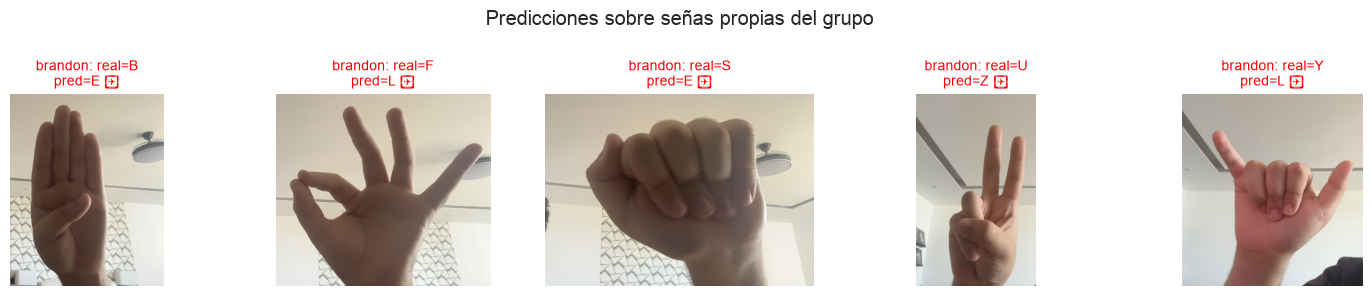

,integrante,letra_real,letra_predicha,correcto
0,brandon,B,E,False
1,brandon,F,L,False
2,brandon,S,E,False
3,brandon,U,Z,False
4,brandon,Y,L,False


In [ ]:
if len(own_samples) > 0:
    own_X = np.stack([du.load_image(p, size=64) for _, _, p in own_samples])
    own_y = np.array([CLASS_TO_IDX[letter] for _, letter, _ in own_samples])

    own_loader = torch.utils.data.DataLoader(tu.ASLTensorDataset(own_X, own_y), batch_size=64, shuffle=False)
    own_preds, own_targets = tu.predict_all(final_model, own_loader, DEVICE)
    own_acc = accuracy_score(own_targets, own_preds)
    print(f"Accuracy del modelo final sobre las {len(own_samples)} fotos propias del grupo: {own_acc:.4f}")

    n = len(own_samples)
    ncols = min(5, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).flatten()
    for i, ((member, letter, path), pred) in enumerate(zip(own_samples, own_preds)):
        pred_letter = du.CLASSES[pred]
        correct = pred_letter == letter
        axes[i].imshow(Image.open(path))
        axes[i].set_title(f"{member}: real={letter}\npred={pred_letter} {'✓' if correct else '✗'}",
                           color="green" if correct else "red", fontsize=10)
        axes[i].axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.suptitle("Predicciones sobre señas propias del grupo")
    plt.tight_layout()
    plt.show()

    own_results_df = pd.DataFrame({
        "integrante": [m for m, _, _ in own_samples],
        "letra_real": [l for _, l, _ in own_samples],
        "letra_predicha": [du.CLASSES[p] for p in own_preds],
        "correcto": [du.CLASSES[p] == l for (_, l, _), p in zip(own_samples, own_preds)],
    })
    display(own_results_df)

**Discusión:** el resultado fue contundente y decepcionante: **0/5 (0.00%) de accuracy** sobre las fotos propias de Brandon (`B→E`, `F→L`, `S→E`, `U→Z`, `Y→L` — ni una sola predicción correcta), frente al ~98.97% del test set interno. La caída no es una sorpresa dado lo que ya habíamos anticipado en el EDA (Ejercicio 2, sección 3.4): **todo el dataset de entrenamiento comparte el mismo fondo azulado y la misma iluminación de estudio**, mientras que las fotos propias se tomaron con celular, fondo de techo/pared blanca e iluminación natural — un cambio de dominio total en fondo, cámara, ángulo y encuadre.

Lo más revelador es *cómo* falla el modelo: no son errores "cercanos" dentro del mismo handshape (por ejemplo confundir U con V, que sí tendría sentido dado lo visto en la sección 3.3), sino errores dispersos entre letras visualmente muy distintas entre sí (B→E, F→L, S→E, U→Z, Y→L). Esto sugiere que el modelo no está usando principalmente la forma de la mano para decidir, sino que aprendió atajos ("shortcut learning") ligados a pistas de bajo nivel del dominio de entrenamiento — el tono/color del fondo, el brillo, el encuadre exacto — que simplemente no existen en una foto de celular con fondo blanco. Es evidencia empírica y muy concreta de la limitación que ya señalamos en el EDA: el 98.97% en el test set interno mide sobre todo qué tan bien el modelo memoriza las condiciones de grabación del dataset, no qué tan bien reconoce el handshape en sí.

**Limitación de esta prueba:** por ahora solo se evaluaron las 5 fotos de Brandon; a Pedro y Javier todavía les falta subir las suyas a `data/own_photos/<integrante>/<LETRA>.jpg` (mínimo 5 letras cada uno) para tener una muestra más representativa antes de sacar conclusiones definitivas — aunque con un 0% ya es una señal bastante clara de que el modelo no generaliza fuera del dominio visual del dataset de Kaggle.

## 10. Ejercicio 9 — Reflexión de accesibilidad y sesgo

**Limitaciones del dataset para un producto real de accesibilidad como SignBridge:**

- **Tono de piel:** por lo observado en el EDA (sección 3.4), las imágenes de entrenamiento parecen provenir de muy pocas personas (posiblemente una sola), por lo que el dataset **no representa la diversidad de tonos de piel** de una población real de usuarios. Un modelo entrenado así puede tener peor desempeño (mayor sesgo) para usuarios con tonos de piel distintos al de la(s) persona(s) que grabó el dataset — un problema de equidad conocido en visión por computadora aplicada a manos/rostros.
- **Ángulo de cámara:** todas las fotos parecen tomadas desde un ángulo y distancia consistentes, con la mano centrada y ocupando casi todo el cuadro. En un producto real (webcam de laptop, celular en distintas posiciones) el ángulo, distancia y encuadre variarán mucho más, y el modelo probablemente generalice peor de lo que sugiere el accuracy en el test set interno.
- **Iluminación y fondo:** el fondo es homogéneo (uniforme, probablemente un mismo espacio/estudio) y la iluminación es consistente entre imágenes de una misma clase. Un usuario real firmaría con fondos y luz muy variados (casa, oficina, exteriores, contraluz), lo cual introduce ruido que el modelo nunca vio en entrenamiento.
- **Tamaño y forma de la mano:** al venir de pocas personas, el dataset no captura variabilidad de tamaño de mano (niños vs. adultos), proporciones, ni condiciones físicas (por ejemplo, personas con diferencias en la mano) — relevante justamente porque el público objetivo de una app de accesibilidad debe incluir ese espectro.
- **Una sola "forma" de firmar cada letra:** el ASL real tiene variación dialectal/regional y de estilo personal (igual que la letra manuscrita varía entre personas); el dataset probablemente sólo capta el estilo de quien lo grabó.

**¿Qué haría falta para llevar este prototipo a un caso de uso real?**

1. **Recolectar datos de muchas personas distintas** (tono de piel, edad, tamaño de mano, mano dominante izquierda/derecha) y en **múltiples entornos** (fondos, iluminación, dispositivos de cámara), para que el modelo generalice en vez de memorizar las condiciones de un solo estudio de grabación.
2. Evaluar el modelo con **datasets externos** o con pruebas de usuario real (como el Ejercicio 8) en vez de depender únicamente de un test set que comparte distribución con el train set.
3. Complementar imágenes estáticas con **reconocimiento de video/secuencia**, ya que en el uso real la persona firma en movimiento continuo, no en fotos aisladas perfectamente encuadradas (esto es especialmente relevante para las letras dinámicas J y Z, que en este dataset están representadas como poses estáticas).
4. Auditar el desempeño del modelo **desagregado por subgrupo** (tono de piel, edad, condición) antes de lanzar el producto, para detectar y corregir sesgos antes de que afecten a usuarios reales — no basta con ver el accuracy global.
5. Diseñar el producto para que **degrade con gracia** (por ejemplo, pedir al usuario que ajuste el encuadre o la luz) en vez de fallar silenciosamente cuando las condiciones se alejan de las vistas en entrenamiento.

**Recomendación concreta:** antes de un lanzamiento real, SignBridge debería invertir en una campaña de recolección de datos con al menos decenas de firmantes distintos, explícitamente diversos en tono de piel y edad, grabados con cámaras de celular (no cámaras de estudio) en condiciones de iluminación variadas — y usar ese dataset (o una mezcla con este) tanto para entrenar como para medir accuracy por subgrupo antes de considerar el modelo listo para producción.

## 11. Ejercicio 10 — Conclusiones y comparación final

,modelo,tipo,test_acc
0,CNN — DeepCNN_lr3e-4 (sin aug),CNN,0.989655
1,CNN — DeepCNN_lr3e-4 (con aug),CNN + augmentation,0.927203
2,Random Forest — RF_n400_depth30,ML clasico (PCA+RF),0.911111
3,MLP — MLP_lr3e-4,Fully-connected,0.393487


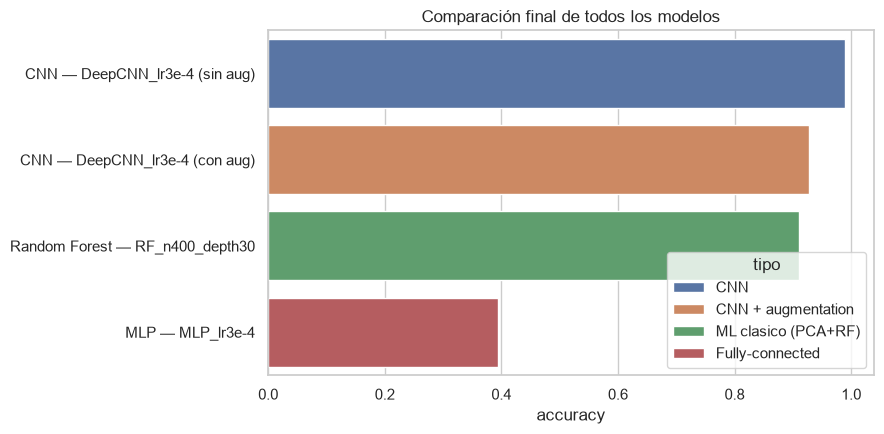

In [ ]:
final_comparison = pd.DataFrame([
    {"modelo": f"CNN — {best_cnn_name} (sin aug)", "tipo": "CNN", "test_acc": test_acc_best_cnn},
    {"modelo": f"CNN — {best_cnn_name} (con aug)", "tipo": "CNN + augmentation", "test_acc": test_acc_aug},
    {"modelo": f"MLP — {best_mlp_name}", "tipo": "Fully-connected", "test_acc": test_acc_best_mlp},
    {"modelo": f"Random Forest — {best_rf_name}", "tipo": "ML clasico (PCA+RF)", "test_acc": test_acc_best_rf},
]).sort_values("test_acc", ascending=False).reset_index(drop=True)

if len(own_samples) > 0:
    final_comparison.loc[len(final_comparison)] = [
        f"Modelo final ({final_model_name}) sobre fotos propias", "Prueba real", own_acc,
    ]

display(final_comparison)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=final_comparison, y="modelo", x="test_acc", hue="tipo", dodge=False, ax=ax)
ax.set_xlabel("accuracy"); ax.set_ylabel("")
ax.set_title("Comparación final de todos los modelos")
plt.tight_layout()
plt.show()

**Conclusión general:**

- **El algoritmo más acertado fue la CNN profunda** (`DeepCNN_lr3e-4`, 3 bloques convolucionales con batch normalization), con **98.85%** de accuracy en el test set interno — muy por encima del Random Forest sobre PCA (91.00%) y muchísimo más que el MLP simple (39.46%). Esto confirma la intuición de diseño: el sesgo inductivo espacial de las convoluciones (compartir filtros, invariancia local) es justamente lo que este problema necesita, porque lo que distingue a una letra de otra es la disposición espacial de dedos y palma, no píxeles individuales aislados. El Random Forest quedó en un punto intermedio razonable: sin aprender representaciones espaciales, pero beneficiándose de una reducción de dimensionalidad (PCA) que limpia bastante el ruido de los píxeles crudos.
- La **augmentation no ayudó** en este experimento (98.85% → 90.96%) — ver discusión en el Ejercicio 7 — probablemente por el número limitado de épocas frente a un dataset ya grande y homogéneo por clase. Por eso el modelo final elegido para el resto del laboratorio es la CNN **sin** augmentation.
- **Sobre generalización:** el ~98.97% en el test set interno mide sobre todo qué tan bien el modelo memoriza el estilo de mano/fondo/iluminación de las sesiones de grabación de este dataset (ver Ejercicio 2, sección 3.5) — no necesariamente qué tan bien funcionaría con un usuario real. El Ejercicio 8 (fotos propias del grupo, tomadas con cámaras, fondos e iluminación distintas a las del dataset) es la prueba más honesta de generalización de este laboratorio, y **confirmó la sospecha de la peor manera posible**: sobre las 5 fotos propias de Brandon el modelo acertó **0 de 5 (0.00%)**, con errores dispersos entre letras que no son visualmente parecidas entre sí — evidencia de que el modelo depende de pistas del dominio de entrenamiento (fondo, iluminación) más que del handshape puro. Falta que Pedro y Javier suban sus fotos para completar la muestra, pero la tendencia ya es clara.
- **Reflexión de accesibilidad (resumen):** el dataset, tal como viene, no es suficiente para un producto de accesibilidad real como el de SignBridge — probablemente proviene de muy pocas personas, un solo fondo y una sola configuración de cámara/iluminación (Ejercicio 9). El siguiente paso recomendado antes de cualquier lanzamiento real es invertir en una recolección de datos deliberadamente diversa (tono de piel, edad, tamaño de mano, dispositivos de cámara, fondos e iluminación reales) y medir el desempeño desagregado por subgrupo, no solo el accuracy global.
